Accuracy: 0.6666666666666666

Confusion Matrix:
[[10  0  0]
 [ 2  4  4]
 [ 0  4  6]]


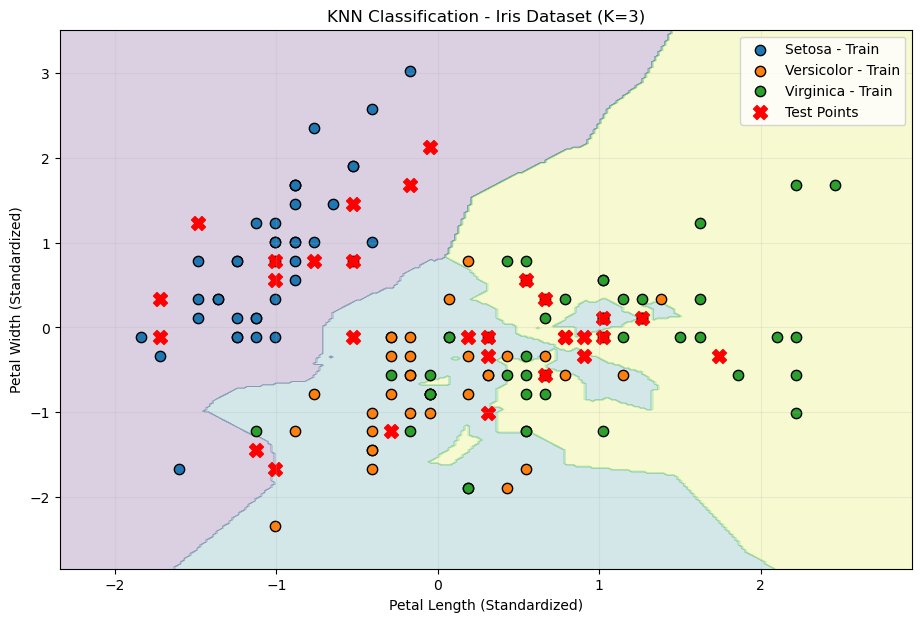

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

# 1. Read Dataset
df = pd.read_csv("data/iris.csv")

# 2. Select Features
X = df[["sepal.length", "sepal.width"]]
y = df["variety"]

# 3. Split Data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 4. Standardize Data
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
k=3
# 5. Create KNN Model
model = KNeighborsClassifier(n_neighbors=k)

# 6. Train Model
model.fit(X_train_scaled, y_train)

# 7. Predict
y_pred = model.predict(X_test_scaled)

# 8. Evaluate Model
accuracy = accuracy_score(y_test, y_pred)

print("Accurac:", accuracy)
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

# 9. Create Mesh Grid for Decision Boundary
x_min, x_max = X_train_scaled[:, 0].min() - 0.5, X_train_scaled[:, 0].max() + 0.5
y_min, y_max = X_train_scaled[:, 1].min() - 0.5, X_train_scaled[:, 1].max() + 0.5

xx, yy = np.meshgrid(
    np.arange(x_min, x_max, 0.02),
    np.arange(y_min, y_max, 0.02)
)

# Predict Every Point in Grid
Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# 10. Plot Decision Boundaries
plt.figure(figsize=(11, 7))

plt.contourf(
    xx, yy, 
    pd.factorize(Z.ravel())[0].reshape(Z.shape),
    alpha=0.2,
    cmap="viridis"
)

# 11. Plot Training Points
for flower in y.unique():
    mask = y_train == flower

    plt.scatter(
        X_train_scaled[mask.to_numpy(), 0],
        X_train_scaled[mask.to_numpy(), 1],
        label=f"{flower} - Train",
        s=55,
        edgecolors="black"
    )

# 12. Plot Test Points
plt.scatter(
    X_test_scaled[:, 0],
    X_test_scaled[:, 1],
    marker="X",
    s=100,
    color="red",
    label="Test Points"
)

# 13. Labels and Title
plt.xlabel("Petal Length (Standardized)")
plt.ylabel("Petal Width (Standardized)")

plt.title(f"KNN Classification - Iris Dataset (K={k})")

plt.legend()
plt.grid(alpha=0.2)
plt.show()
